# Event Study

This notebook estimates how a treatment effect changes with time since a common treatment date. CausalPy's `EventStudy` is the simultaneous-adoption design: every treated unit adopts at the same time. Settings where units adopt at different times are {term}`Staggered Difference-in-Differences`, not this estimator.

## What is being estimated

Write event time as $k = t - g$, where $g$ is the common treatment date. The regression is a two-way fixed-effects model with one indicator for each event time except a reference period $k_0$:

$$Y_{it} = \alpha_i + \lambda_t + \sum_{k \neq k_0} \tau_k \, 1\{t - g = k\} D_i + \varepsilon_{it}$$

$D_i$ is 1 for units that are eventually treated. $\tau_k$ is the outcome gap between treated and never-treated units at event time $k$, relative to the gap at $k_0$. The reference coefficient is exactly zero because that indicator is omitted. It is not an estimated effect.

:::{note}
This is not a license to use the same regression for staggered adoption. When treatment dates differ, two-way fixed effects can put negative weight on some cohort comparisons {cite:p}`sun2021estimating,callaway2021difference,roth2023whats`. Use `StaggeredDifferenceInDifferences` for that design.
:::

The causal reading needs a {term}`parallel trends assumption`: absent treatment, the treated and never-treated groups would have moved together. Pre-treatment $\tau_k$ are the usual check of that claim. They are not proof of it.


In [1]:
import causalpy as cp
from causalpy.data.simulate_data import generate_event_study_data

## Simulate a simultaneous-adoption panel

The simulator builds a balanced panel. Treated units share one treatment time. Never-treated units have a missing treatment time. `treatment_effects` maps event time to the outcome jump added for treated units. Here the effect is zero before treatment and rises after adoption.


In [3]:
df = generate_event_study_data(
    n_units=24,
    n_time=16,
    treatment_time=8,
    treated_fraction=0.5,
    treatment_effects={0: 1.5, 1: 1.8, 2: 2.0, 3: 2.2, 4: 2.4},
    seed=42,
)
df.head()

,unit,time,y,treat_time,treated
0,0,0,0.372216,8.0,1
1,0,1,0.586449,8.0,1
2,0,2,-0.101912,8.0,1
3,0,3,0.624342,8.0,1
4,0,4,-0.099310,8.0,1


## Configure, then fit

`EventStudy` checks the panel and builds the design at construction. It does not sample until `fit()`. The formula supplies unit and time intercepts. The experiment adds the event-time indicators itself, so do not put those terms in the formula.

The default window is the last four pre-treatment periods through the first four post-treatment periods, and the omitted period is the last pre-treatment period.


In [5]:
result = cp.EventStudy(
    df,
    formula="y ~ 1 + C(unit) + C(time)",
    unit_col="unit",
    time_col="time",
    treat_time_col="treat_time",
    event_window=(-4, 4),
    reference_event_time=-1,
    model=cp.pymc_models.LinearRegression(
        sample_kwargs={
            "draws": 1000,
            "tune": 1000,
            "chains": 4,
            "cores": 1,
            "progressbar": False,
            "random_seed": 42,
        }
    ),
).fit()
result.effect_summary()

EffectSummary(table=   event_time      mean    median  hdi_lower  hdi_upper  is_reference   p_gt_0
0          -4  0.057165  0.056475  -0.113764   0.215940         False  0.74975
1          -3 -0.005175 -0.005019  -0.166916   0.160495         False  0.47475
2          -2 -0.093521 -0.094158  -0.260192   0.066411         False  0.13075
3          -1  0.000000  0.000000        NaN        NaN          True      NaN
4           0  1.499421  1.497093   1.340507   1.669118         False  1.00000
5           1  1.998735  1.998100   1.846863   2.167265         False  1.00000
6           2  1.981702  1.981691   1.818278   2.148035         False  1.00000
7           3  2.163283  2.163549   1.994798   2.322578         False  1.00000
8           4  2.372551  2.372010   2.197263   2.522656         False  1.00000, text="Dynamic treatment effects are relative to event time -1 (window (-4, 4)). The reference coefficient is normalized to zero. This is a simultaneous-adoption event study, not a staggered

## Plot the event-time curve

Points are posterior means. Bars are highest-density intervals. The open point at the reference event time is the omitted category, fixed at zero.


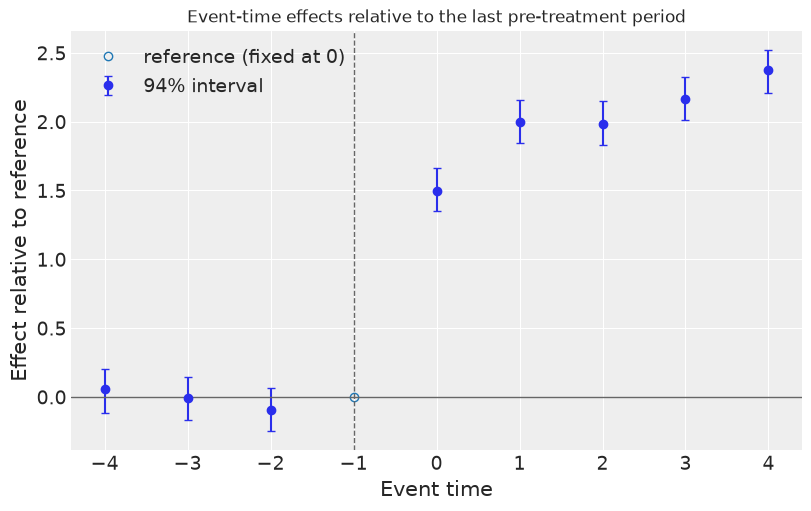

In [7]:
fig, ax = result.plot(show=False)
ax.set_title("Event-time effects relative to the last pre-treatment period")
fig

## Reading the result

Post-treatment coefficients should sit above zero in this simulation, because the data-generating process adds a positive effect at adoption and a smaller increment at each later event time. Pre-treatment coefficients should sit near zero. A pre-treatment interval that excludes zero is a warning about the parallel-trends claim, not a treatment effect.

`get_plot_data()` returns the same numbers as a table. The reference row has mean zero and no interval, because there is no posterior draw for an omitted coefficient.


In [9]:
result.get_plot_data()

,event_time,mean,is_reference,std,hdi_lower,hdi_upper
0,-4,0.057165,False,0.084596,-0.113387,0.203223
1,-3,-0.005175,False,0.083541,-0.166916,0.145478
2,-2,-0.093521,False,0.082499,-0.248173,0.065692
3,-1,0.000000,True,NaN,NaN,NaN
4,0,1.499421,False,0.083936,1.349769,1.663272
5,1,1.998735,False,0.082886,1.847947,2.155613
6,2,1.981702,False,0.084767,1.829101,2.147993
7,3,2.163283,False,0.083297,2.009395,2.322936
8,4,2.372551,False,0.083338,2.211069,2.522656


## What this estimator will not do

`EventStudy` raises if treated units have different treatment times. That is intentional: the simultaneous-adoption regression answers a different question from a staggered estimator, and silently pooling those designs hides the negative-weight problem.

An ordinary least-squares model uses the same design. Its summary reports point estimates and says that uncertainty is not available, rather than inventing intervals.

:::{bibliography}
:filter: docname in docnames
:::
